# Blockpose detector — current synthetic milestone

This is the reproducible **seed 0** status of the geometry-only detector. Green boxes are
detections. Dashed orange boxes and all matching/error numbers are **evaluation-only labels**;
the detector never receives synthetic instance IDs, poses, or locations.

Current milestone: cutoff-aware evaluation, richer raycast degradations, local ground-plane
height, known-dimension top+side center recovery, and stratified diagnostics. Real-data
validation (Phase D) has landed now that snapshots ship a per-capture `tf.yaml`; see the
dedicated section below.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / ".."]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "pyproject.toml").is_file() and (candidate / "python/blockpose").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root from notebook working directory")


REPO_ROOT = find_repo_root()
for path in (REPO_ROOT / "python", REPO_ROOT / "tools"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from blockpose.detection import DetectionParams, detect_scene_sample
from blockpose.evaluate import evaluate
from blockpose.pose import BLOCK_DIMS
from blockpose.scenario_matrix import generate_scenario_matrix
import eval_detector

SEED = 0
CASES = {case.name: sample for case, sample in generate_scenario_matrix(SEED)}

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
def box_edges(pose, dims=BLOCK_DIMS):
    half = np.asarray(dims) / 2
    corners = np.array([[x, y, z] for x in (-half[0], half[0])
                        for y in (-half[1], half[1]) for z in (-half[2], half[2])])
    corners = (pose.rotation @ corners.T).T + pose.position
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8)
             if np.count_nonzero(np.array([(i >> k) & 1 for k in range(3)]) !=
                                 np.array([(j >> k) & 1 for k in range(3)])) == 1]
    return [(corners[i], corners[j]) for i, j in edges]


def set_equal_3d(ax, arrays, padding=0.06, min_span=0.5):
    finite = [np.asarray(a, float).reshape(-1, 3) for a in arrays if np.asarray(a).size]
    points = np.vstack(finite) if finite else np.zeros((1, 3))
    points = points[np.all(np.isfinite(points), axis=1)]
    if not len(points):
        points = np.zeros((1, 3))
    low, high = points.min(axis=0), points.max(axis=0)
    spans = np.maximum(high - low, min_span)
    spans *= 1.0 + 2.0 * padding
    center = (low + high) / 2.0
    ax.set_xlim(center[0] - spans[0] / 2, center[0] + spans[0] / 2)
    ax.set_ylim(center[1] - spans[1] / 2, center[1] + spans[1] / 2)
    ax.set_zlim(center[2] - spans[2] / 2, center[2] + spans[2] / 2)
    ax.set_box_aspect(spans)


def overlay(name, title):
    sample = CASES[name]
    detections = detect_scene_sample(sample, DetectionParams())
    result = evaluate(detections, sample.ground_truth)
    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection="3d")
    stride = max(len(sample.points) // 10000, 1)
    shown = sample.points[::stride]
    plotted = [shown]
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.35, c="0.55", alpha=0.35)
    for pose in sample.ground_truth:
        for a, b in box_edges(pose, pose.dims):
            ax.plot(*zip(a, b), color="tab:orange", linestyle="--", linewidth=1.2)
            plotted.append(np.vstack([a, b]))
    for pose in detections:
        for a, b in box_edges(pose, pose.dims):
            ax.plot(*zip(a, b), color="tab:green", linewidth=1.8)
            plotted.append(np.vstack([a, b]))
    set_equal_3d(ax, plotted)
    ax.set(title=title, xlabel="world X [m]", ylabel="world Y [m]", zlabel="world Z [m]")
    ax.view_init(elev=24, azim=-58)
    print({"matched": result.matched, "FP": result.unmatched_det, "FN": result.unmatched_gt,
           "translation_p95_m": result.translation_p95_m,
           "rotation_p95_deg": result.rotation_p95_deg})
    plt.show()
    return detections, result

## Success case

The dashed orange cuboid below is an **evaluation-only label**. At seed 0 the isolated tilted
case is recovered with centimeter-scale center error; it is representative of the current
well-observed top-plus-side operating regime.

{'matched': 1, 'FP': 0, 'FN': 0, 'translation_p95_m': 0.20575015507650404, 'rotation_p95_deg': 88.87920882778526}


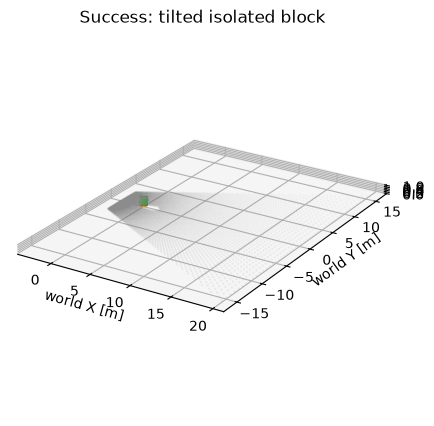

In [3]:
success_det, success_eval = overlay('isolated_tilt_7deg', 'Success: tilted isolated block')

## Compact gate and stratified baseline

Only the original isolated suite is gated. The scenario matrix is deliberately diagnostic:
weak families remain visible instead of being averaged into the success number.

In [4]:
metrics = eval_detector.run_suite(seed=SEED)
print("GATE", {key: metrics[key] for key in
      ("recall", "precision", "translation_p95_m", "rotation_p95_deg",
       "false_positives_empty")})
print("\nSTRATIFIED DIAGNOSTICS")


def fmt(value):
    return f"{value:.2f}" if value is not None else "n/a"


for family, values in metrics["diagnostics_stratified"].items():
    print(f"{family:16s} recall={fmt(values['recall'])} precision={fmt(values['precision'])} "
          f"FP={values['false_positives']} t_p95={values['translation_p95_m']}")

GATE {'recall': 1.0, 'precision': 1.0, 'translation_p95_m': 0.005658134472191571, 'rotation_p95_deg': 0.21905638325971377, 'false_positives_empty': 0}

STRATIFIED DIAGNOSTICS
isolated_range   recall=1.00 precision=1.00 FP=0 t_p95=0.000570173276601229
tilt             recall=1.00 precision=1.00 FP=0 t_p95=0.0003694365102042381
noise            recall=1.00 precision=1.00 FP=0 t_p95=0.004728196164641558
dropout          recall=1.00 precision=1.00 FP=0 t_p95=0.0002752095269807708
multi_block      recall=1.00 precision=1.00 FP=0 t_p95=0.00035340473001516445
touching         recall=0.00 precision=n/a FP=0 t_p95=None
stack            recall=0.83 precision=1.00 FP=0 t_p95=0.005317690147715955
clutter          recall=1.00 precision=1.00 FP=0 t_p95=0.0004065528637778752
hard_negative    recall=n/a precision=n/a FP=0 t_p95=None
standoff         recall=0.50 precision=1.00 FP=0 t_p95=0.0012797561951941568
uneven_ground    recall=0.80 precision=1.00 FP=0 t_p95=0.00077899651110152
sensor_artifacts re

## Validity calibration deferred

Confidence estimates whether a returned detection is valid; it is separate from pose
observability and must not filter detections until calibrated. The current selected-output
synthetic corpus contains too few organic false positives to fit or evaluate a validity
calibrator honestly. `calibrated_confidence` therefore remains `None`, and calibration is deferred
until harder organic synthetic errors and real TF-aligned data are available.

In [5]:
print("Calibration status: BLOCKED — insufficient selected-output organic negatives")

Calibration status: BLOCKED — insufficient selected-output organic negatives


## Hard-negative improvement and honest named failures

**Touching row:** blocks in contact (a seamless row) have no measured internal interface and are
geometrically equivalent to one elongated cuboid. The detector conservatively emits no blocks
instead of inventing three from outer extent alone. This is the same missing-interface gap that
blocks wall-course separation on real assembly geometry — still open.

**Hard-negative-only:** ground-relative known-height evidence rejects these shorter boxes.

**Two-block stack:** only the observable top block is recovered. The buried interface supplies no
surface evidence, so the lower pose must not be invented from the synthetic layout.

**Far range:** optional sensor context now scales geometric support thresholds by expected
range-dependent angular density, recovering this sparse case without location-specific tuning.
The `standoff` family in the stratified diagnostics above tracks the same range-dependent recall
cliff (~15-20 m) at finer granularity.

{'matched': 0, 'FP': 0, 'FN': 3, 'translation_p95_m': None, 'rotation_p95_deg': None}


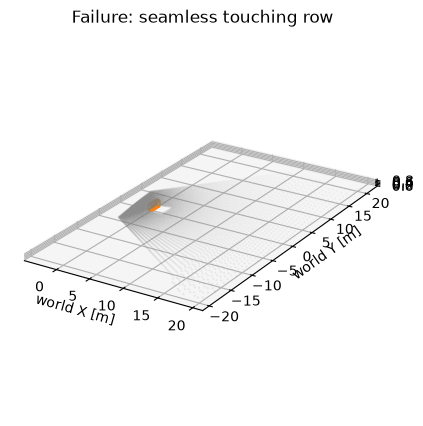

{'matched': 0, 'FP': 2, 'FN': 0, 'translation_p95_m': None, 'rotation_p95_deg': None}


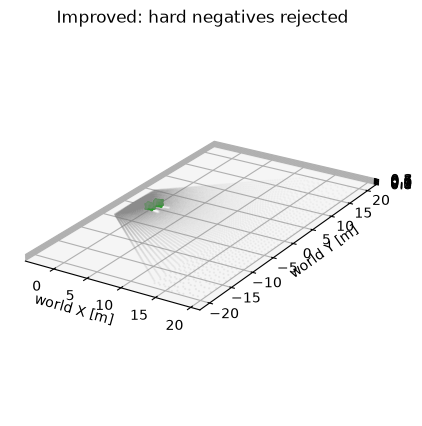

{'matched': 1, 'FP': 0, 'FN': 1, 'translation_p95_m': 0.15039593720147104, 'rotation_p95_deg': 90.00556220698284}


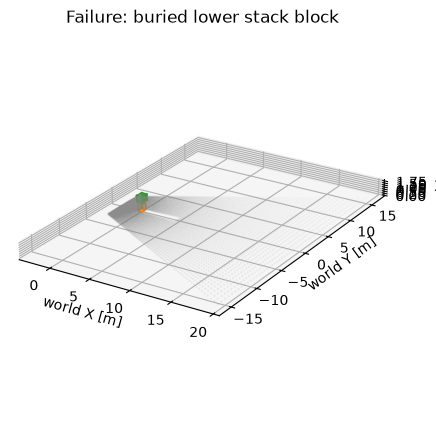

{'matched': 1, 'FP': 0, 'FN': 0, 'translation_p95_m': 0.19661348630503078, 'rotation_p95_deg': 88.55139444143944}


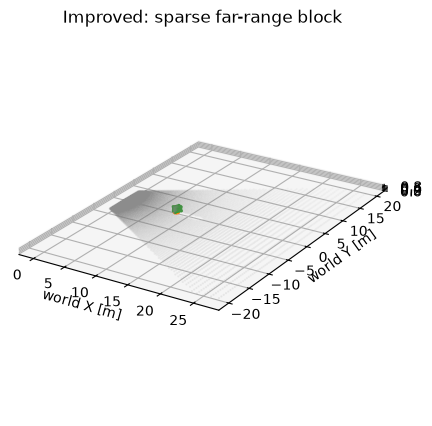

In [6]:
touching_det, touching_eval = overlay("touching_row", "Failure: seamless touching row")
negative_det, negative_eval = overlay("hard_negative_only", "Improved: hard negatives rejected")
stack_det, stack_eval = overlay("two_stack", "Failure: buried lower stack block")
far_det, far_eval = overlay("isolated_far", "Improved: sparse far-range block")

## Real-data validation (Phase D)

Snapshots now ship a per-capture `tf.yaml` (the crane's actual joint state at the moment the
frame was taken). The static reference-pose config used before this misplaced the cloud by
several metres relative to recorded ground truth on at least one snapshot — enough that 0 of 3
blocks matched until the detector switched to using it.

Two caveats apply to everything below, unlike the synthetic sections above:

- **Ground truth is not exact.** `registrations.yaml` is itself the output of the upstream
  RGB-based registration pipeline, which can fail to register a real block it detected
  (`registration_ok: false`). An unmatched detection in a low/zero-GT snapshot may be a real,
  un-registered block, not a false positive — see `tools/eval_real_snapshots.py`'s docstring.
- **This is four snapshots, not a statistically meaningful sample.** Treat the numbers below as
  directional, and re-run `tools/eval_real_snapshots.py` as more real data lands.

Two concrete fixes came out of this validation pass:

1. Real callers weren't providing `SensorContext`, so the detector's free-space/visibility
   evidence (needed to tell a laid block's long face from its short face) was silently inactive.
   `SensorContext.from_points(origin, points)` derives ray directions/ranges from the returns
   themselves — no true sensor misses available from a plain cloud, but enough to drop mean
   rotation error on 2 of 3 blocks in one snapshot from ~87° to ~1.5°. It also changed *which*
   block got recovered — one, sitting close to the crane/gripper arm, now drops out — a real,
   unresolved recall/orientation-accuracy trade-off.
2. Hypothesis selection had no minimum quality bar, so a plausible-shaped cluster on the
   crane/gripper hardware was reported as a detection. `DetectionParams.min_score` (default 0.0,
   so every synthetic scenario above is unaffected) rejects it: real spurious hypotheses scored
   under ~0.2 on the available snapshots, every confirmed real block scored over ~0.4.

{'matched': 2, 'unmatched_det': 0, 'unmatched_gt': 1, 'translation_p95_m': 0.013398871390282108, 'rotation_p95_deg': 1.6557181512865717}


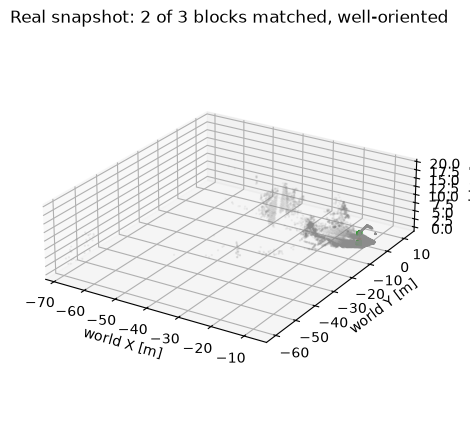

In [7]:
import eval_real_snapshots
from blockpose.detection import SensorContext, detect_blocks_detailed
from blockpose.io import load_snapshot, load_tf_snapshot

REAL_DETECTION_PARAMS = DetectionParams(min_score=0.4)


def real_overlay(snapshot_name, title, params=REAL_DETECTION_PARAMS):
    snap_dir = REPO_ROOT / "data" / "registration_snapshots" / snapshot_name
    tf_snapshot = load_tf_snapshot(snap_dir / "tf.yaml")
    pts_world, gt = load_snapshot(snap_dir, T_world_cloud=tf_snapshot.T_world_cloud)
    sensor_origin = tf_snapshot.T_world_cloud[:3, 3]
    context = SensorContext.from_points(sensor_origin, pts_world)
    detections = detect_blocks_detailed(pts_world, params, sensor_context=context).poses

    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection="3d")
    stride = max(len(pts_world) // 10000, 1)
    shown = pts_world[::stride]
    plotted = [shown]
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.35, c="0.55", alpha=0.35)
    for pose in gt:
        for a, b in box_edges(pose, pose.dims):
            ax.plot(*zip(a, b), color="tab:orange", linestyle="--", linewidth=1.2)
            plotted.append(np.vstack([a, b]))
    for pose in detections:
        for a, b in box_edges(pose, pose.dims):
            ax.plot(*zip(a, b), color="tab:green", linewidth=1.8)
            plotted.append(np.vstack([a, b]))
    set_equal_3d(ax, plotted)
    ax.set(title=title, xlabel="world X [m]", ylabel="world Y [m]", zlabel="world Z [m]")
    ax.view_init(elev=24, azim=-58)
    if gt:
        result = evaluate(detections, gt)
        print({"matched": result.matched, "unmatched_det": result.unmatched_det,
               "unmatched_gt": result.unmatched_gt,
               "translation_p95_m": result.translation_p95_m,
               "rotation_p95_deg": result.rotation_p95_deg})
    else:
        result = None
        print(f"{len(detections)} detection(s); snapshot has no registered ground truth "
              "(see caveat above)")
    plt.show()
    return detections, result


real_det, real_eval = real_overlay(
    "1783429044_018652416_seq1", "Real snapshot: 2 of 3 blocks matched, well-oriented"
)

### Aggregate real-snapshot metrics

Same harness as `tools/eval_real_snapshots.py`, run here for the checked-in snapshots.

In [8]:
real_metrics = eval_real_snapshots.run_suite(
    REPO_ROOT / "data" / "registration_snapshots",
    REPO_ROOT / "config" / "transforms_pzs100_initial_pose_1.yaml",
    REAL_DETECTION_PARAMS,
)
print({key: real_metrics[key] for key in (
    "n_snapshots_scored", "n_snapshots_with_zero_gt", "recall",
    "precision_grounded_snapshots_only", "translation_p95_m", "rotation_p95_deg",
)})
for entry in real_metrics["per_snapshot"]:
    print(f"  {entry['snapshot']}: gt={entry['gt_blocks']} detected={entry['detected']} "
          f"matched={entry['matched']}")

{'n_snapshots_scored': 4, 'n_snapshots_with_zero_gt': 2, 'recall': 0.75, 'precision_grounded_snapshots_only': 1.0, 'translation_p95_m': 0.025950797585086838, 'rotation_p95_deg': 1.5349214770118926}
  1783428141_224458752_seq3: gt=0 detected=2 matched=0
  1783429044_018652416_seq1: gt=3 detected=2 matched=2
  1783429057_917983488_seq2: gt=0 detected=0 matched=0
  1783429345_020967424_seq4: gt=1 detected=1 matched=1


## Next detector architecture

```text
validated cloud + sensor origin
  → local ground frame + permissive connected regions
  → PlanePatch extraction (normal, equation, residual, hull, coverage)
  → multiple known-size CuboidHypothesis proposals per region
  → deterministic HypothesisEvidence
       surface support + face coverage + dimension consistency
       expected-visible missing faces + free-space violations + overlap
  → robust box refinement
  → score-ordered selection / explained-point discounting
  → pose + observability + calibrated confidence + diagnostics
```

The next acceptance targets are richer face coverage and calibrated evidence. Stacked blocks
with buried interfaces must be reported as unobservable unless visible geometry supplies enough
evidence; layout priors must not masquerade as measurements.